# Cedalion AR-IRLS vs fixAR-IRLS vs AR-iRRR: mnt-correct HRF, all subjects

This notebook summarizes the results of `cmp_AR-IRLS_fixAR-IRLS_AR-iRRR.py`, for every subject that has a saved result
(`derivatives/eeg/{subject}/{subject}_mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR.pkl`).
It only reads the saved results and figures; nothing is refit.

All three models share the same `Y` and the same event-based design matrix, and are trained on all three runs. There is no test set, so the comparison is about **how much the estimated HRFs agree**, not about prediction.

| Model | Noise model | Fit |
|---|---|---|
| **AR-IRLS** | Cedalion `glm.fit(noise_model='ar_irls')`, AR order ≤ 30, re-estimated per parcel | robust IRLS per parcel |
| **fixAR-IRLS** | one spectral-whitening kernel from the OLS residuals, averaged over parcels, applied to the concatenated `Y` and `X` | robust IRLS per parcel (Tukey biweight, c = 4.685) |
| **AR-iRRR** | same whitened (and `Y_scale`-scaled) `Y` and `X` as fixAR-IRLS | iRRR, all parcels jointly; λ₁ = smallest penalty that gives rank 2 |

Contents:
1. Pipeline
2. Fit summary: `Y_scale`, iRRR λ₁ and rank
3. HRF agreement between models (per-parcel correlation over HRF time)
4. HRF amplitude: how much each model shrinks the HRF
5. Standard errors: AR-IRLS vs fixAR-IRLS
6. Group HRF: `ContA` network mean and its most sensitive parcel
7. Group HRF of every network (all 17, then the 12 main networks in a fixed order)
8. Spatial maps of HRF agreement
9. AR-iRRR temporal components
10. Per-subject figures
11. Summary

## 1. Pipeline

### 1a. Inputs
- **fNIRS**: parcel time series from image reconstruction (probe Adot v26, `derivatives/cedalion/pipeline_reorder/processed_data`), **HbO** only. Parcels are kept if their forward-model sensitivity is `log10(Σ_channel A) > −2`; the medial wall, the `scalp` parcel, and any parcel that is not finite in all three runs are dropped.
- **Subjects**: every folder in `processed_data` with both input files, minus `excluded_subj`.
- **Events**: mnt trials with `response_code == 0` (**mnt-correct**).

### 1b. Per-run preprocessing
1. **Highpass** the full run: 4th-order Butterworth, 0.02 Hz, zero-phase.
2. **Regressors** on the full run: 12 consecutive Gaussian kernels (−2 to 10 s, Δ = 1 s, σ = 1 s) locked to the mnt-correct onsets. Building them before truncation keeps the full kernel of trials near the window edges.
3. **Truncate** `Y` and the regressors to the trial window (first onset → last onset + 15 s).
4. **Drift**: OLS-regress out Legendre polynomials.
5. **GSR**: OLS-regress out the global mean (computed from the drift residuals).

### 1c. Fit (runs concatenated in the order `gradcpt1, 2, 3`)
- **AR-IRLS**: Cedalion AR-IRLS on the concatenated runs.
- **fixAR-IRLS**: OLS of `Y ~ run intercepts + X`; the residuals give one spectral whitening kernel (averaged over parcels), applied to the concatenated `Y` and `X` as a single series. The whitened `Y` is divided by its std (`Y_scale`), then IRLS per parcel. Betas are scaled back to M.
- **AR-iRRR**: iRRR on the same whitened, scaled `Y` and `X`. λ₁ is scanned on `10^(−3 : 0.125 : 2)`, and the smallest λ₁ whose coefficient matrix has rank 2 is kept (bisection if no grid point hits rank 2).

The HRF of each parcel is `B · β`, where `B` is the (time × 12) Gaussian basis. The SE of the IRLS HRFs is `sqrt(diag(B Σ_β Bᵀ))`; iRRR has no SE.

In [1]:
%matplotlib inline
import os, sys, glob, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Image, display

sys.path.insert(0, os.getcwd())
from params_setting import project_path

model_name = 'mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR'
select_chromo = 'HbO'
models = ['AR-IRLS', 'fixAR-IRLS', 'AR-iRRR']
keys = {'AR-IRLS': 'ar_irls', 'fixAR-IRLS': 'fixar_irls', 'AR-iRRR': 'ar_irrr'}
colors = {'AR-IRLS': 'C0', 'fixAR-IRLS': 'C3', 'AR-iRRR': 'C2'}   # same as in the script
pairs = ['AR-IRLS vs fixAR-IRLS', 'AR-IRLS vs AR-iRRR', 'fixAR-IRLS vs AR-iRRR']
pair_colors = dict(zip(pairs, ['#7b5ea7', '#2a9d8f', '#e07a1f']))
to_uM = 1e6

eeg_der_dir = os.path.join(project_path, 'derivatives', 'eeg')
plot_root = os.path.join(eeg_der_dir, 'HRF_surf')
group_dir = os.path.join(plot_root, 'group', model_name)
fig_dir = os.path.join(group_dir, 'summary_nb')
os.makedirs(fig_dir, exist_ok=True)

files = sorted(glob.glob(os.path.join(eeg_der_dir, 'sub-*', f'sub-*_{model_name}.pkl')))
res = {}
for f in files:
    with open(f, 'rb') as fh:
        r = pickle.load(fh)
    res[r['subject']] = r
subjects = list(res)
r0 = res[subjects[0]]
hrf_t = r0['hrf_t']
select_network = r0['select_network']
print(f"{len(subjects)} subjects: {subjects}")
print(f"parcels per subject: {sorted({len(r['parcels']) for r in res.values()})}; "
      f"{select_network} parcels: {sorted({len(r['network_parcels']) for r in res.values()})}")
print(f"most sensitive {select_network} parcel: {pd.Series({s: r['select_parcel'] for s, r in res.items()}).value_counts().to_dict()}")

20 subjects: ['sub-629', 'sub-634', 'sub-636', 'sub-637', 'sub-642', 'sub-643', 'sub-656', 'sub-659', 'sub-661', 'sub-668', 'sub-670', 'sub-681', 'sub-695', 'sub-719', 'sub-721', 'sub-723', 'sub-726', 'sub-727', 'sub-730', 'sub-751']
parcels per subject: [417]; ContA parcels: [31]
most sensitive ContA parcel: {'ContA_PFCl_5_RH': 20}


## 2. Fit summary
- `Y_scale` is the std of the whitened, concatenated `Y` (M). It is shared by fixAR-IRLS and AR-iRRR.
- `irrr_lam1` is the selected λ₁; `bisected` marks a λ₁ that is not on the scan grid.
- `scan ranks` lists the ranks reached across the λ₁ scan (from the smallest to the largest λ₁).

In [2]:
grid = 10 ** np.arange(-3, 2.01, 0.125)
fit_df = pd.DataFrame({
    s: {'Y_scale (M)': r['fixar_irls']['Y_scale'],
        'irrr_lam1': r['ar_irrr']['irrr_lam1'],
        'bisected': not np.isclose(grid, r['ar_irrr']['irrr_lam1']).any(),
        'iRRR rank': int(r['ar_irrr']['rank']),
        'scan ranks': ' '.join(str(int(f['rank'])) for f in r['ar_irrr']['scan'])}
    for s, r in res.items()}).T
display(fit_df.style.format({'Y_scale (M)': '{:.3g}', 'irrr_lam1': '{:.3g}'}))
print(fit_df[['Y_scale (M)', 'irrr_lam1']].astype(float).describe().loc[['mean', 'std', 'min', 'max']].to_string(float_format='{:.3g}'.format))

,Y_scale (M),irrr_lam1,bisected,iRRR rank,scan ranks
sub-629,3.19e-08,0.274,True,2,12 12 12 12 12 12 12 11 12 11 11 11 11 10 10 8 8 8 6 4 2 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
sub-634,2.05e-08,0.422,False,2,12 12 12 12 12 12 12 11 12 11 10 12 12 11 10 9 9 7 6 6 3 2 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
sub-636,3.25e-08,0.365,True,2,12 12 12 12 12 12 12 11 11 11 9 11 12 11 10 10 9 7 7 6 3 2 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
sub-637,2.33e-08,0.562,False,2,12 12 12 12 12 12 12 11 11 11 10 11 10 9 9 7 7 7 6 6 5 3 2 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
sub-642,1.98e-08,0.422,False,2,12 12 12 12 12 12 12 11 11 11 10 11 11 10 9 8 8 8 7 4 3 2 2 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
sub-643,2.45e-08,0.365,True,2,12 12 12 12 12 12 12 11 12 11 10 12 11 10 10 9 8 8 8 6 3 2 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
sub-656,2.36e-08,0.274,True,2,12 12 12 12 12 12 12 11 12 11 11 12 10 9 9 8 6 6 5 3 2 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
sub-659,2.18e-08,0.422,False,2,12 12 12 12 12 12 11 11 11 10 10 11 11 10 10 9 8 8 8 6 5 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
sub-661,2.08e-08,0.294,True,2,12 12 12 11 12 12 11 10 11 10 10 9 11 10 10 8 6 6 5 5 3 2 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
sub-668,2.24e-08,0.237,False,2,12 12 12 12 12 12 12 12 12 12 11 12 10 10 9 7 7 6 4 2 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0


      Y_scale (M)  irrr_lam1
mean     2.29e-08      0.341
std      5.15e-09     0.0836
min      1.37e-08      0.205
max      3.44e-08      0.562


## 3. HRF agreement between models

For every parcel, `r` is the Pearson correlation between two models' HRFs over the HRF time axis (−2 to 10 s). It measures agreement in **shape** only, not amplitude (see section 4 for amplitude).

**Left/middle:** per-subject median `r`, over all parcels and over the `ContA` parcels. **Right:** the pooled distribution of per-parcel `r` across all subjects.

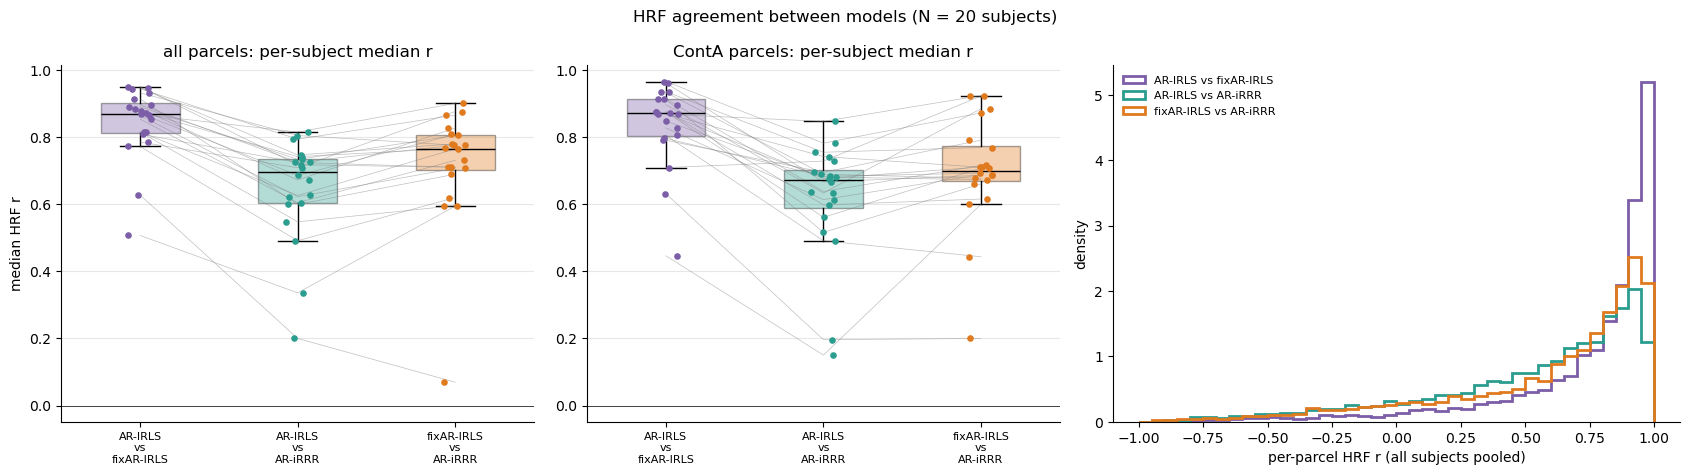

In [3]:
corr_long = pd.concat({s: r['hrf_corr'] for s, r in res.items()}, names=['subject', 'parcel'])
med_rows = []
for s, r in res.items():
    for scope, idx in [('all', r['parcels']), (select_network, r['network_parcels'])]:
        for p in pairs:
            med_rows.append({'subject': s, 'parcels': scope, 'pair': p, 'median r': r['hrf_corr'].loc[idx, p].median()})
med_corr = pd.DataFrame(med_rows)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1, 1, 1.2]})
rng = np.random.default_rng(0)
for ax, scope in zip(axes[:2], ['all', select_network]):
    d = med_corr[med_corr.parcels == scope]
    vals = [d.loc[d.pair == p, 'median r'].values for p in pairs]
    bp = ax.boxplot(vals, showfliers=False, widths=0.5, patch_artist=True, medianprops={'color': 'k'})
    for b, p in zip(bp['boxes'], pairs):
        b.set_facecolor(pair_colors[p]); b.set_alpha(0.35)
    # connect each subject across pairs
    wide = d.pivot(index='subject', columns='pair', values='median r')[pairs]
    for s, row in wide.iterrows():
        ax.plot(np.arange(1, 4), row.values, color='gray', lw=0.5, alpha=0.5)
    for i, v in enumerate(vals):
        ax.scatter(np.full(len(v), i + 1) + rng.uniform(-0.08, 0.08, len(v)), v, s=14, color=pair_colors[pairs[i]], zorder=3)
    ax.set_xticks(np.arange(1, 4), [p.replace(' vs ', '\nvs\n') for p in pairs], fontsize=8)
    ax.axhline(0, color='k', lw=0.5)
    ax.set_title(f'{scope} parcels: per-subject median r')
    ax.grid(alpha=0.3, axis='y'); ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('median HRF r')
axes[1].sharey(axes[0])
bins = np.linspace(-1, 1, 41)
for p in pairs:
    axes[2].hist(corr_long[p].dropna(), bins=bins, histtype='step', lw=2, color=pair_colors[p], density=True, label=p)
axes[2].set_xlabel('per-parcel HRF r (all subjects pooled)')
axes[2].set_ylabel('density')
axes[2].legend(frameon=False, fontsize=8, loc='upper left')
axes[2].spines[['top', 'right']].set_visible(False)
fig.suptitle(f'HRF agreement between models (N = {len(subjects)} subjects)')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'hrf_corr_box_hist.png'), dpi=150)
plt.show()

In [4]:
wide = med_corr.pivot_table(index='subject', columns=['parcels', 'pair'], values='median r')[['all', select_network]]
display(wide.style.format('{:.2f}').background_gradient(cmap='RdBu_r', vmin=-1, vmax=1, axis=None)
        .set_caption('Per-subject median HRF r'))

# share of parcels with low agreement, per pair (pooled)
frac = pd.DataFrame({thr: (corr_long < thr).mean() for thr in [0, 0.5]}).rename(columns=lambda t: f'frac r < {t}')
summ = med_corr.groupby(['parcels', 'pair'])['median r'].agg(['mean', 'median', 'min', 'max'])
display(summ.round(3))
display(frac.round(3).rename_axis('pair (pooled parcels)'))

# paired Wilcoxon tests between pairs, on the per-subject median r (all parcels)
w = wide['all']
for a, b in [(pairs[0], pairs[1]), (pairs[0], pairs[2]), (pairs[2], pairs[1])]:
    st = stats.wilcoxon(w[a], w[b])
    print(f"{a}  >  {b}: {(w[a] > w[b]).sum()}/{len(w)} subjects, Wilcoxon p = {st.pvalue:.2g}")

mean  median    min    max
parcels pair                                              
ContA   AR-IRLS vs AR-iRRR     0.617   0.671  0.150  0.847
        AR-IRLS vs fixAR-IRLS  0.837   0.871  0.446  0.966
        fixAR-IRLS vs AR-iRRR  0.697   0.700  0.200  0.924
all     AR-IRLS vs AR-iRRR     0.645   0.697  0.200  0.815
        AR-IRLS vs fixAR-IRLS  0.841   0.869  0.507  0.950
        fixAR-IRLS vs AR-iRRR  0.719   0.766  0.069  0.901

,frac r < 0.0,frac r < 0.5
pair (pooled parcels),,
AR-IRLS vs fixAR-IRLS,0.050,0.170
AR-IRLS vs AR-iRRR,0.128,0.366
fixAR-IRLS vs AR-iRRR,0.114,0.298


AR-IRLS vs fixAR-IRLS  >  AR-IRLS vs AR-iRRR: 20/20 subjects, Wilcoxon p = 1.9e-06
AR-IRLS vs fixAR-IRLS  >  fixAR-IRLS vs AR-iRRR: 17/20 subjects, Wilcoxon p = 0.00032
fixAR-IRLS vs AR-iRRR  >  AR-IRLS vs AR-iRRR: 16/20 subjects, Wilcoxon p = 0.0012


## 4. HRF amplitude

iRRR shrinks the coefficient matrix through the nuclear-norm penalty, and fixAR-IRLS and AR-IRLS use different whitening, so the HRFs can agree in shape but not in size. Here the amplitude of a parcel's HRF is its **RMS over HRF time** (µM).

**Left:** per-subject median RMS of each model. **Right:** per-subject median of the per-parcel ratio RMS(model) / RMS(AR-IRLS).

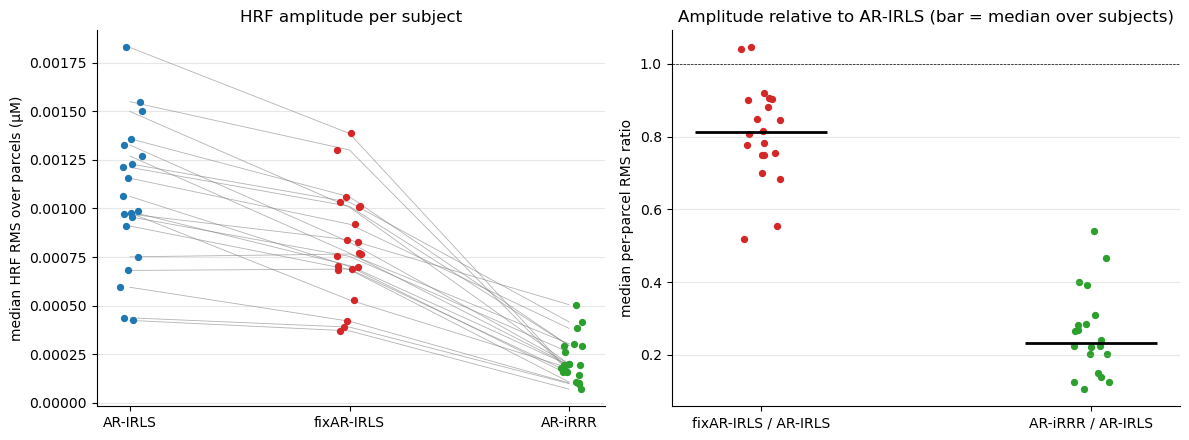

,RMS µM: AR-IRLS,RMS µM: fixAR-IRLS,RMS µM: AR-iRRR,fixAR-IRLS / AR-IRLS,AR-iRRR / AR-IRLS
sub-629,0.00183,0.00139,0.000164,0.754,0.106
sub-634,0.000681,0.000688,0.000158,1.04,0.267
sub-636,0.0015,0.00101,0.000199,0.777,0.15
sub-637,0.00123,0.00103,0.000416,0.88,0.4
sub-642,0.000971,0.000838,0.000505,0.907,0.541
sub-643,0.00121,0.00101,0.000294,0.901,0.311
sub-656,0.00155,0.0013,0.00016,0.848,0.126
sub-659,0.00106,0.000701,0.000144,0.553,0.126
sub-661,0.000594,0.00042,0.000102,0.816,0.222
sub-668,0.00133,0.000827,0.0002,0.75,0.24


In [5]:
def rms(h):
    return np.sqrt((h.values ** 2).mean(axis=1)) * to_uM

amp = {s: pd.DataFrame({m: rms(r[keys[m]]['hrf']) for m in models}, index=r['parcels']) for s, r in res.items()}
amp_med = pd.DataFrame({s: a.median() for s, a in amp.items()}).T
ratio_med = pd.DataFrame({s: {f'{m} / AR-IRLS': (a[m] / a['AR-IRLS']).median() for m in models[1:]} for s, a in amp.items()}).T

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
for s in subjects:
    ax.plot(range(3), amp_med.loc[s, models].values, color='gray', lw=0.6, alpha=0.6)
for i, m in enumerate(models):
    ax.scatter(np.full(len(subjects), i) + rng.uniform(-0.06, 0.06, len(subjects)), amp_med[m], color=colors[m], s=18, zorder=3)
ax.set_xticks(range(3), models)
ax.set_ylabel('median HRF RMS over parcels (µM)')
ax.set_title('HRF amplitude per subject')
ax = axes[1]
for i, c in enumerate(ratio_med.columns):
    m = c.split(' / ')[0]
    ax.scatter(np.full(len(subjects), i) + rng.uniform(-0.06, 0.06, len(subjects)), ratio_med[c], color=colors[m], s=18)
    ax.hlines(ratio_med[c].median(), i - 0.2, i + 0.2, color='k', lw=2)
ax.axhline(1, color='k', lw=0.5, ls='--')
ax.set_xticks(range(2), ratio_med.columns)
ax.set_ylabel('median per-parcel RMS ratio')
ax.set_title('Amplitude relative to AR-IRLS (bar = median over subjects)')
for ax in axes:
    ax.grid(alpha=0.3, axis='y'); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'hrf_amplitude.png'), dpi=150)
plt.show()
display(pd.concat([amp_med.add_prefix('RMS µM: '), ratio_med], axis=1).style.format('{:.3g}'))

## 5. Standard errors: AR-IRLS vs fixAR-IRLS

Both IRLS models give a covariance of the basis betas, so each has an HRF SE. A smaller SE with the same HRF would mean a more efficient (or overconfident) noise model. Below: the per-parcel ratio SE(fixAR-IRLS) / SE(AR-IRLS), averaged over HRF time, and the resulting peak |t| = max over time of |HRF / SE| for each model.

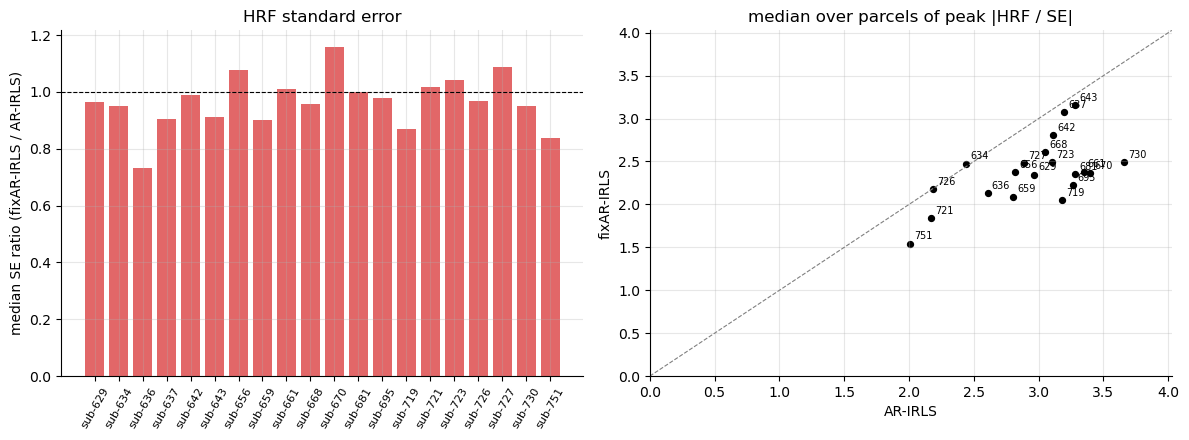

,median SE ratio (fix / AR),median peak |t| AR-IRLS,median peak |t| fixAR-IRLS,"frac parcels peak |t| > 3, AR-IRLS","frac parcels peak |t| > 3, fixAR-IRLS"
subject,,,,,
sub-629,0.963,2.97,2.35,0.492,0.283
sub-634,0.95,2.44,2.47,0.269,0.348
sub-636,0.733,2.61,2.13,0.357,0.24
sub-637,0.905,3.19,3.08,0.566,0.523
sub-642,0.99,3.11,2.81,0.549,0.434
sub-643,0.91,3.28,3.15,0.585,0.535
sub-656,1.08,2.82,2.38,0.439,0.259
sub-659,0.9,2.8,2.09,0.484,0.177
sub-661,1.01,3.35,2.38,0.592,0.29


In [6]:
se_rows = []
for s, r in res.items():
    se_ar = r['ar_irls']['hrf_se'].values
    se_fix = r['fixar_irls']['hrf_se'].values
    t_ar = np.abs(r['ar_irls']['hrf'].values / se_ar).max(1)
    t_fix = np.abs(r['fixar_irls']['hrf'].values / se_fix).max(1)
    se_rows.append({'subject': s,
                    'median SE ratio (fix / AR)': np.median(se_fix.mean(1) / se_ar.mean(1)),
                    'median peak |t| AR-IRLS': np.median(t_ar), 'median peak |t| fixAR-IRLS': np.median(t_fix),
                    'frac parcels peak |t| > 3, AR-IRLS': (t_ar > 3).mean(),
                    'frac parcels peak |t| > 3, fixAR-IRLS': (t_fix > 3).mean()})
se_df = pd.DataFrame(se_rows).set_index('subject')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(range(len(subjects)), se_df['median SE ratio (fix / AR)'], color='C3', alpha=0.7)
axes[0].axhline(1, color='k', lw=0.8, ls='--')
axes[0].set_xticks(range(len(subjects)), subjects, rotation=60, fontsize=8)
axes[0].set_ylabel('median SE ratio (fixAR-IRLS / AR-IRLS)')
axes[0].set_title('HRF standard error')
lim = se_df[['median peak |t| AR-IRLS', 'median peak |t| fixAR-IRLS']].values.max() * 1.1
axes[1].scatter(se_df['median peak |t| AR-IRLS'], se_df['median peak |t| fixAR-IRLS'], color='k', s=18)
for s, row in se_df.iterrows():
    axes[1].annotate(s[4:], (row['median peak |t| AR-IRLS'], row['median peak |t| fixAR-IRLS']), fontsize=7,
                     xytext=(3, 3), textcoords='offset points')
axes[1].plot([0, lim], [0, lim], color='gray', lw=0.8, ls='--')
axes[1].set_xlim(0, lim); axes[1].set_ylim(0, lim)
axes[1].set_xlabel('AR-IRLS'); axes[1].set_ylabel('fixAR-IRLS')
axes[1].set_title('median over parcels of peak |HRF / SE|')
for ax in axes:
    ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'hrf_se.png'), dpi=150)
plt.show()
display(se_df.style.format('{:.3g}'))

## 6. Group HRF

Mean ± SEM across subjects of (left) each subject's `ContA` network-mean HRF and (right) the HRF at the most sensitive `ContA` parcel. The bottom row shows every subject's HRF at the most sensitive parcel, one panel per model, on a shared y axis.

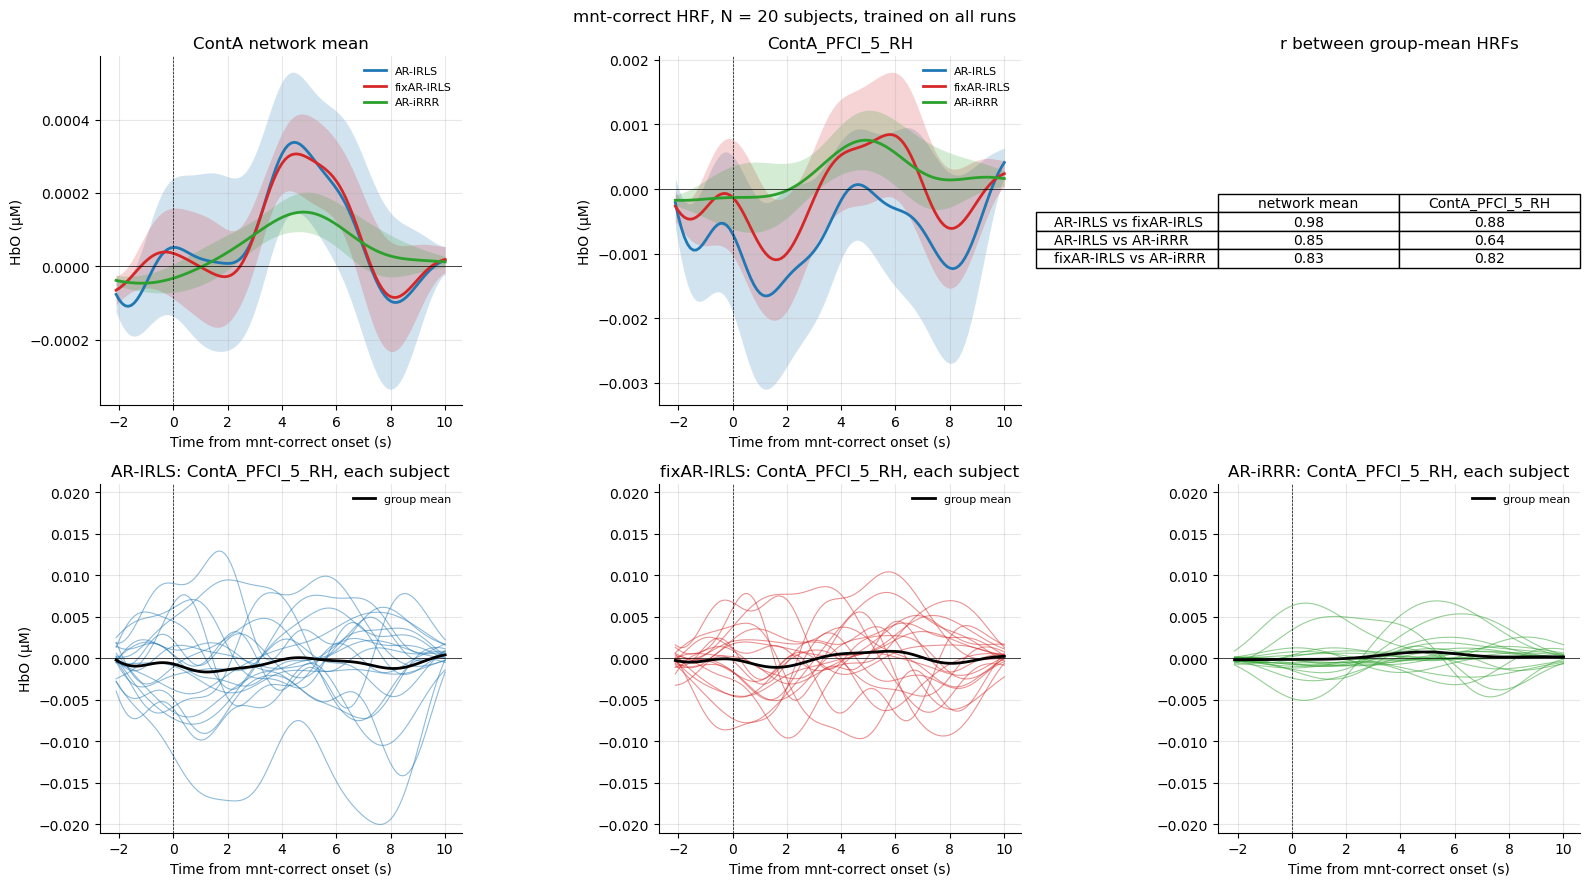

In [7]:
sel_parcel = r0['select_parcel']
get = {f'{select_network} network mean': lambda r, k: r[k]['hrf'].sel(parcel=r['network_parcels']).mean('parcel').values,
       f'{sel_parcel}': lambda r, k: r[k]['hrf'].sel(parcel=r['select_parcel']).values}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (title, g) in zip(axes[0, :2], get.items()):
    for m in models:
        h = np.stack([g(r, keys[m]) for r in res.values()]) * to_uM
        mu, sem = h.mean(0), h.std(0, ddof=1) / np.sqrt(len(h))
        ax.fill_between(hrf_t, mu - sem, mu + sem, color=colors[m], alpha=0.2, lw=0)
        ax.plot(hrf_t, mu, color=colors[m], lw=2, label=m)
    ax.set_title(title)
    ax.set_ylabel(f'{select_chromo} (µM)')
    ax.legend(fontsize=8, frameon=False)
# group-mean shape correlation between models
ax = axes[0, 2]
gm = {m: np.stack([get[f'{sel_parcel}'](r, keys[m]) for r in res.values()]).mean(0) for m in models}
gn = {m: np.stack([get[f'{select_network} network mean'](r, keys[m]) for r in res.values()]).mean(0) for m in models}
tbl = pd.DataFrame({'network mean': {p: np.corrcoef(gn[p.split(' vs ')[0]], gn[p.split(' vs ')[1]])[0, 1] for p in pairs},
                    sel_parcel: {p: np.corrcoef(gm[p.split(' vs ')[0]], gm[p.split(' vs ')[1]])[0, 1] for p in pairs}})
ax.axis('off')
ax.table(cellText=tbl.round(2).values, rowLabels=tbl.index, colLabels=tbl.columns, loc='center', cellLoc='center')
ax.set_title('r between group-mean HRFs')

ylim = np.max([np.abs(get[sel_parcel](r, keys[m])).max() for r in res.values() for m in models]) * to_uM * 1.05
for ax, m in zip(axes[1], models):
    for r in res.values():
        ax.plot(hrf_t, get[sel_parcel](r, keys[m]) * to_uM, color=colors[m], lw=0.8, alpha=0.5)
    ax.plot(hrf_t, gm[m] * to_uM, color='k', lw=2, label='group mean')
    ax.set_ylim(-ylim, ylim)
    ax.set_title(f'{m}: {sel_parcel}, each subject')
    ax.legend(fontsize=8, frameon=False)
for ax in axes.flat:
    if ax.has_data():
        ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5, ls='--')
        ax.set_xlabel('Time from mnt-correct onset (s)')
        ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
axes[1, 0].set_ylabel(f'{select_chromo} (µM)')
fig.suptitle(f'mnt-correct HRF, N = {len(subjects)} subjects, trained on all runs')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'group_hrf.png'), dpi=150)
plt.show()

## 7. Group HRF of every network (all 17, then the 12 main networks in a fixed order)

For each network: each subject's HRF is averaged over the network's parcels, then the mean across subjects is plotted with a t-based 95% CI (`sem · t₀.₉₇₅(N−1)`). All three models are shown in each panel. Each panel has its own y axis.

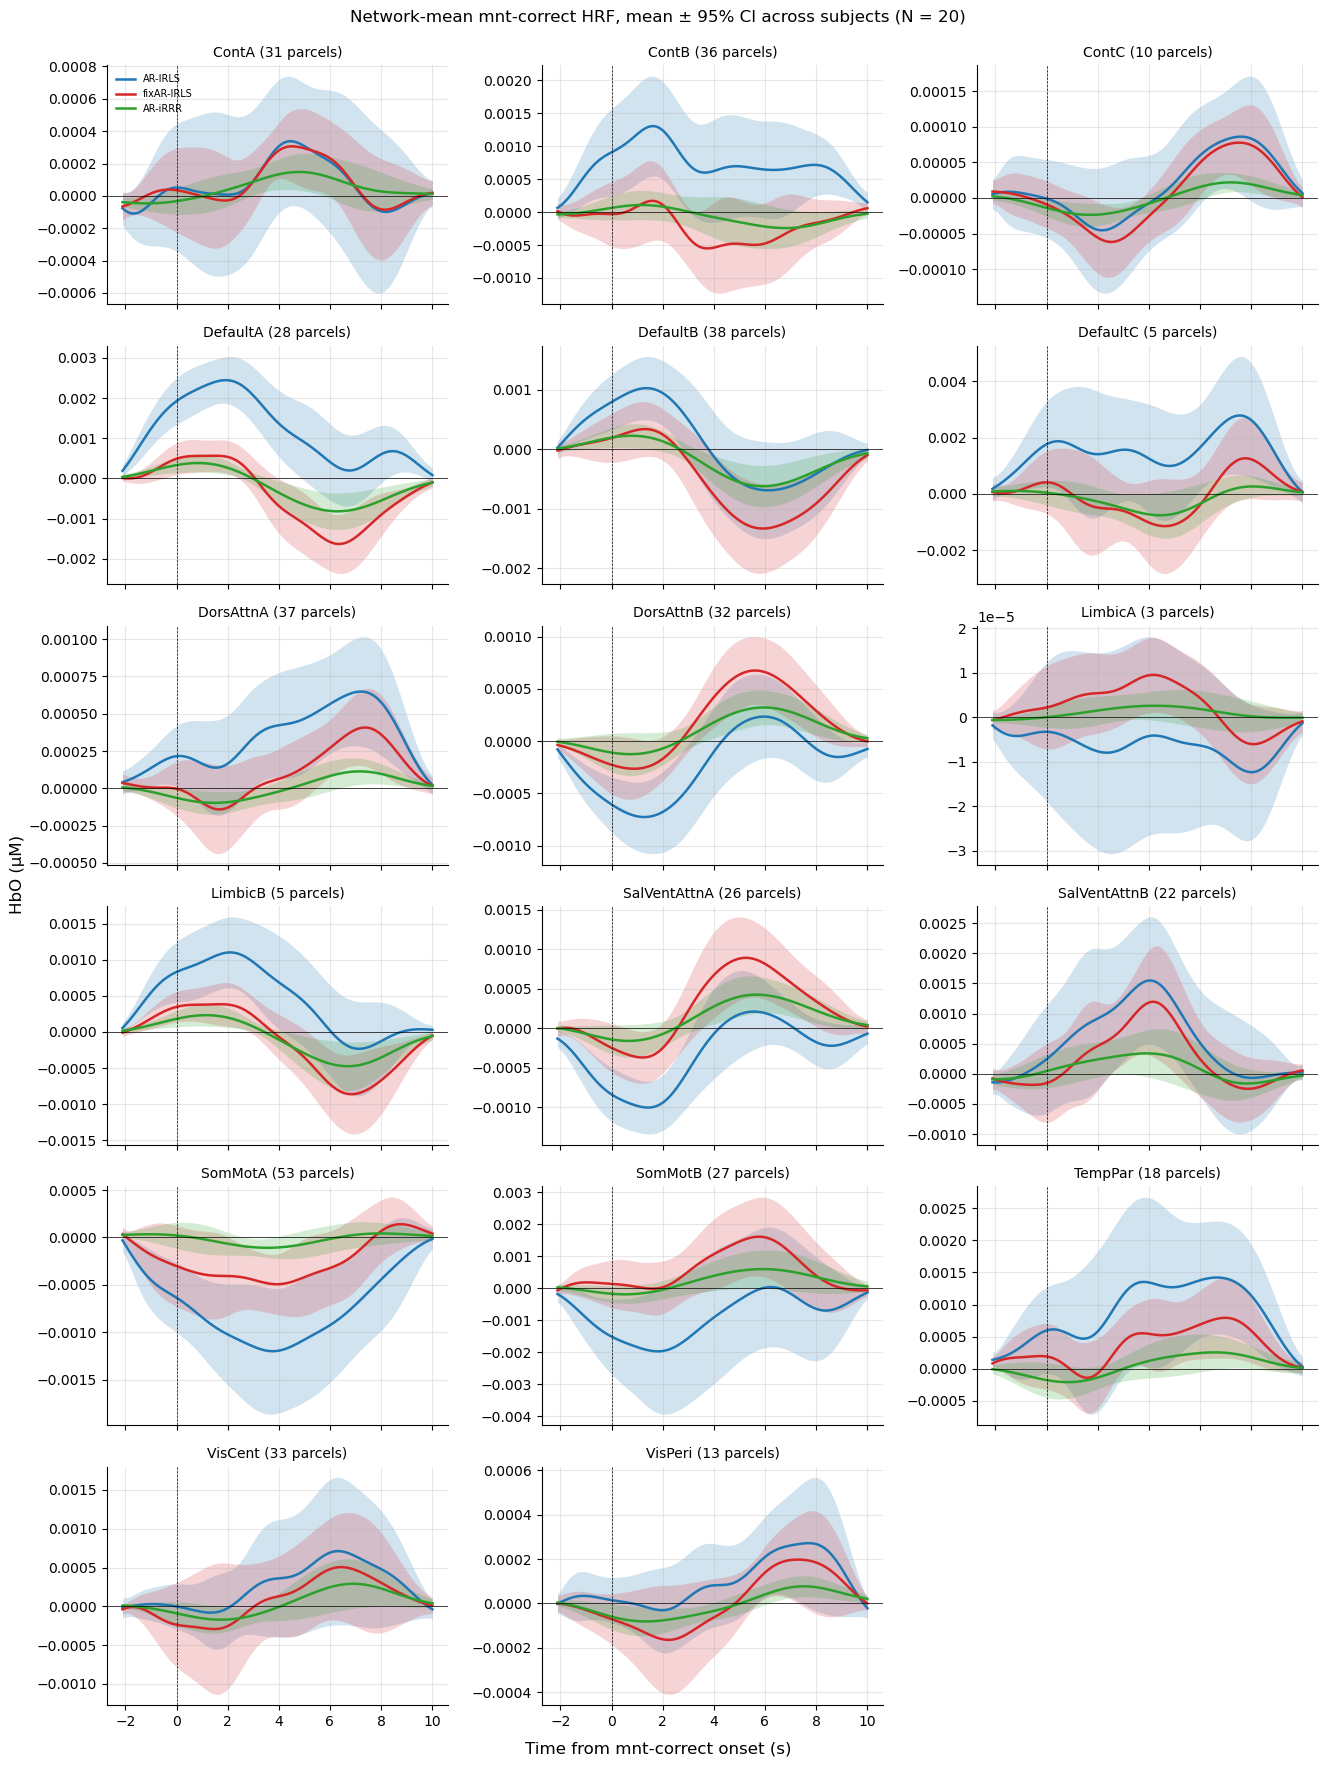

,n parcels,AR-IRLS vs fixAR-IRLS,AR-IRLS vs AR-iRRR,fixAR-IRLS vs AR-iRRR
network,,,,
ContA,31,0.98,0.85,0.83
ContB,36,0.26,0.46,0.65
ContC,10,0.99,0.97,0.96
DefaultA,28,0.76,0.75,0.99
DefaultB,38,0.95,0.95,1.00
DefaultC,5,0.52,0.23,0.93
DorsAttnA,37,0.85,0.72,0.96
DorsAttnB,32,0.92,0.94,0.99
LimbicA,3,0.48,-0.07,0.79


In [8]:
networks = sorted({p.split('_')[0] for p in r0['parcels']})
n_cols = 3
n_rows = int(np.ceil(len(networks) / n_cols))
fig, axs = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 3 * n_rows), 
                        sharex=True, sharey=False)
axs = np.atleast_1d(axs).flatten()
net_rows = []
for ax, net in zip(axs, networks):
    net_mean = {}
    for m in models:
        # subjects x HRF time
        subj_hrf_net = np.stack([
            r[keys[m]]['hrf'].sel(parcel=[p for p in r['parcels'] if p.split('_')[0] == net]).mean('parcel').values
            for r in res.values()
        ]) * to_uM
        n_subj = subj_hrf_net.shape[0]
        mean_hrf = subj_hrf_net.mean(axis=0)
        ci95 = stats.sem(subj_hrf_net, axis=0) * stats.t.ppf(0.975, n_subj - 1)
        ax.fill_between(hrf_t, mean_hrf - ci95, mean_hrf + ci95, color=colors[m], alpha=0.2, lw=0)
        ax.plot(hrf_t, mean_hrf, color=colors[m], lw=1.8, label=m)
        net_mean[m] = mean_hrf
    n_par = sum(p.split('_')[0] == net for p in r0['parcels'])
    net_rows.append({'network': net, 'n parcels': n_par,
                     **{p: np.corrcoef(net_mean[p.split(' vs ')[0]], net_mean[p.split(' vs ')[1]])[0, 1] for p in pairs}})
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5, ls='--')
    ax.set_title(f'{net} ({n_par} parcels)', fontsize=10)
    ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
for ax in axs[len(networks):]:
    ax.set_visible(False)
axs[0].legend(fontsize=7, frameon=False)
fig.supxlabel('Time from mnt-correct onset (s)')
fig.supylabel(f'{select_chromo} (µM)')
fig.suptitle(f'Network-mean mnt-correct HRF, mean ± 95% CI across subjects (N = {len(subjects)})')
fig.tight_layout(rect=(0, 0, 1, 0.985))
fig.savefig(os.path.join(fig_dir, 'group_hrf_all_networks.png'), dpi=150)
plt.show()

net_corr = pd.DataFrame(net_rows).set_index('network')
display(net_corr.style.format({p: '{:.2f}' for p in pairs}).background_gradient(cmap='RdBu_r', vmin=-1, vmax=1, subset=pairs)
        .set_caption('r between the group-mean network HRFs of each pair of models'))

The same plot for the 12 main networks, in a fixed order on a 3 × 4 grid. ContC, DefaultC, LimbicA/B and VisPeri are left out. Each panel has its own y axis.

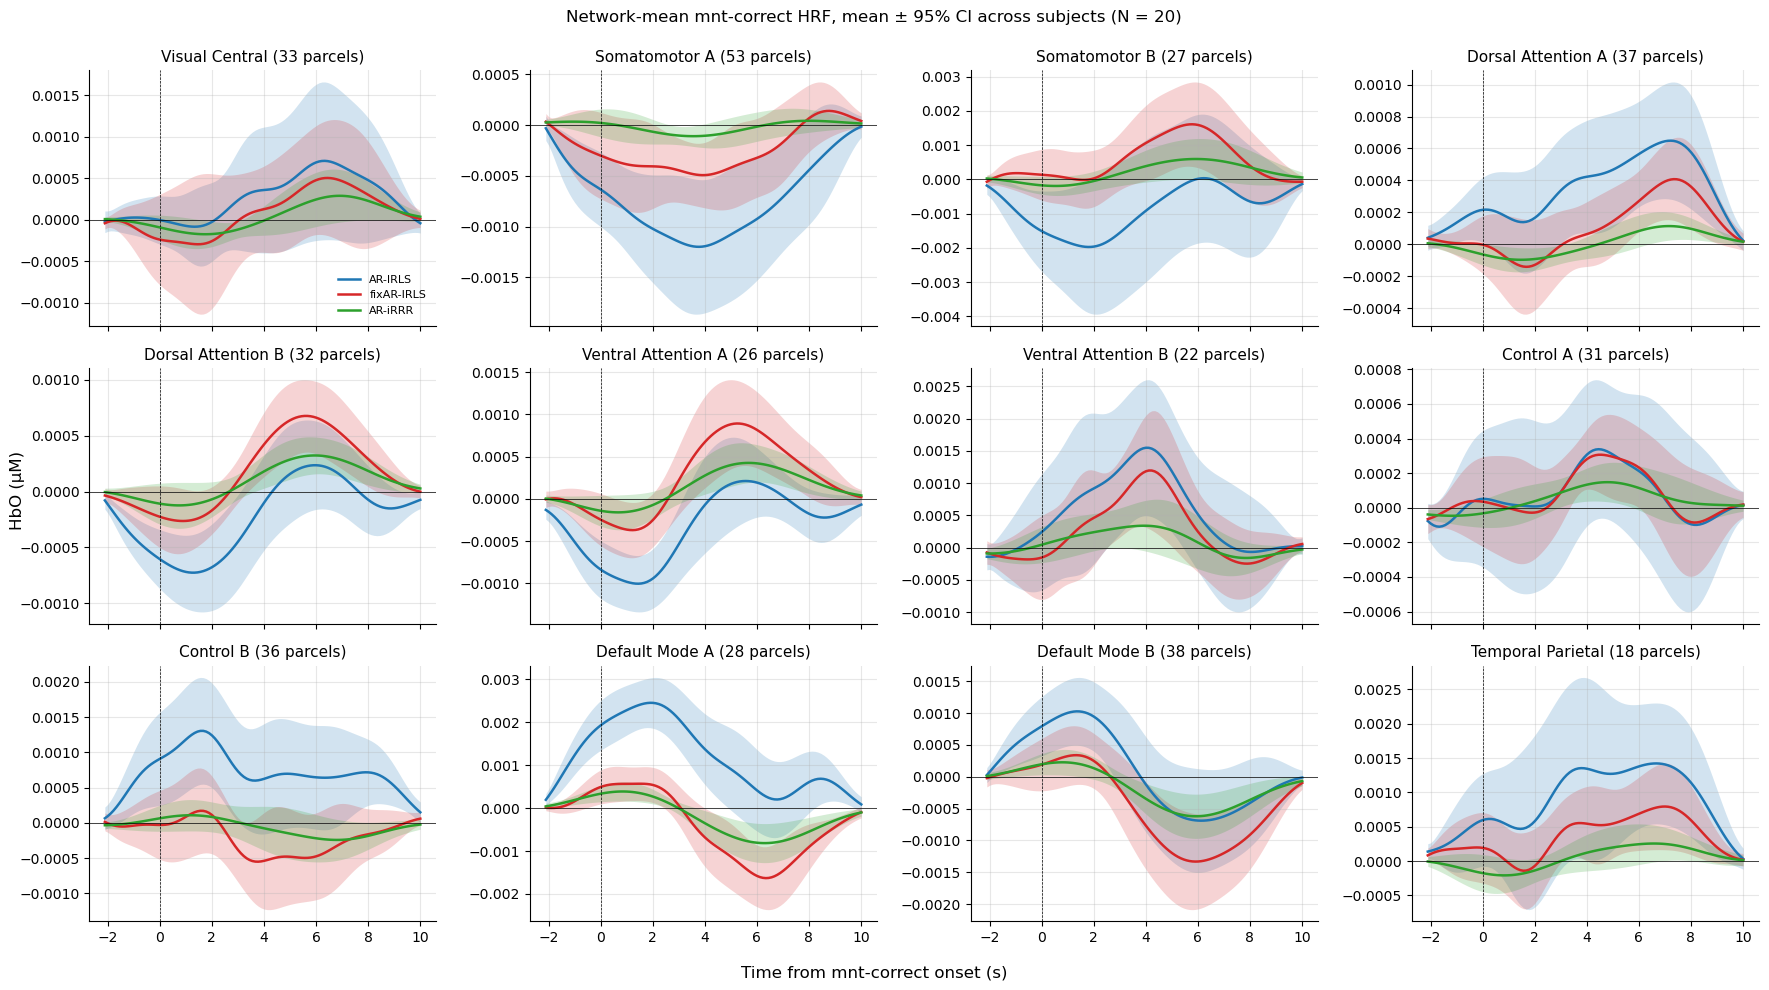

In [9]:
network_order = {   # parcel prefix -> panel title
    'VisCent': 'Visual Central', 'SomMotA': 'Somatomotor A', 'SomMotB': 'Somatomotor B',
    'DorsAttnA': 'Dorsal Attention A', 'DorsAttnB': 'Dorsal Attention B',
    'SalVentAttnA': 'Ventral Attention A', 'SalVentAttnB': 'Ventral Attention B',
    'ContA': 'Control A', 'ContB': 'Control B',
    'DefaultA': 'Default Mode A', 'DefaultB': 'Default Mode B', 'TempPar': 'Temporal Parietal',
}
fig, axs = plt.subplots(3, 4, figsize=(18, 10), sharex=True, sharey=False)
for ax, (net, net_title) in zip(axs.flat, network_order.items()):
    for m in models:
        # subjects x HRF time
        subj_hrf_net = np.stack([
            r[keys[m]]['hrf'].sel(parcel=[p for p in r['parcels'] if p.split('_')[0] == net]).mean('parcel').values
            for r in res.values()
        ]) * to_uM
        n_subj = subj_hrf_net.shape[0]
        mean_hrf = subj_hrf_net.mean(axis=0)
        ci95 = stats.sem(subj_hrf_net, axis=0) * stats.t.ppf(0.975, n_subj - 1)
        ax.fill_between(hrf_t, mean_hrf - ci95, mean_hrf + ci95, color=colors[m], alpha=0.2, lw=0)
        ax.plot(hrf_t, mean_hrf, color=colors[m], lw=1.8, label=m)
    n_par = sum(p.split('_')[0] == net for p in r0['parcels'])
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5, ls='--')
    ax.set_title(f'{net_title} ({n_par} parcels)', fontsize=11)
    ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
axs.flat[0].legend(fontsize=8, frameon=False)
fig.supxlabel('Time from mnt-correct onset (s)')
fig.supylabel(f'{select_chromo} (µM)')
fig.suptitle(f'Network-mean mnt-correct HRF, mean ± 95% CI across subjects (N = {len(subjects)})')
fig.tight_layout(rect=(0, 0, 1, 0.985))
fig.savefig(os.path.join(fig_dir, 'group_hrf_12_networks.png'), dpi=150)
plt.show()

## 8. Spatial maps of HRF agreement

Mean over subjects of the per-parcel HRF `r` for each pair of models (saved by the script; gray = not fitted). Blue = disagreement, red = agreement.

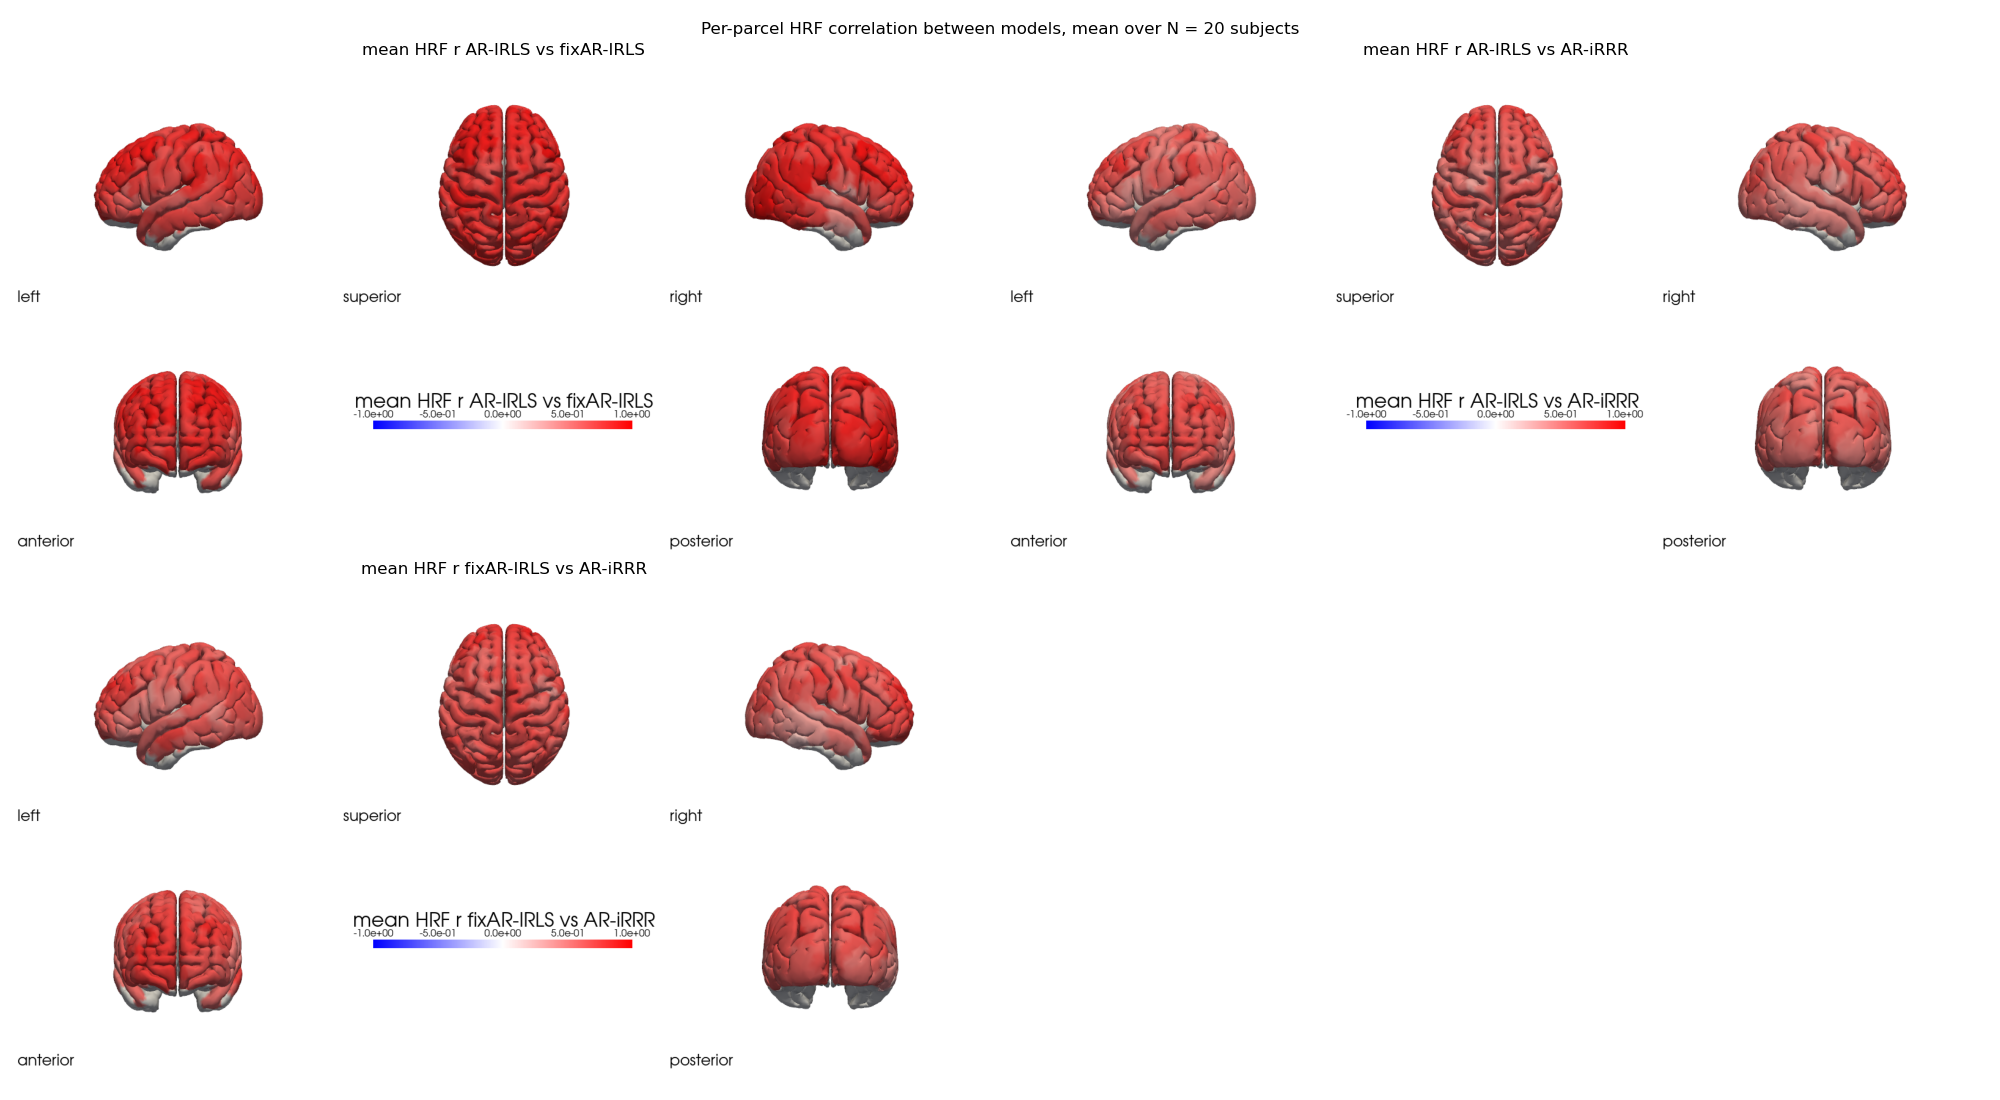

In [10]:
display(Image(os.path.join(group_dir, 'group_hrf_corr_surf.png'), width=1100))

Is agreement related to forward-model sensitivity? Per-parcel mean `r` (over subjects) vs log10 parcel sensitivity. The sensitivity is recomputed from the Adot exactly as in the script.

/projectnb/stephenlab/cchang1/.conda/envs/cedalion/lib/python3.11/site-packages/xarray/computation/apply_ufunc.py:814: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)


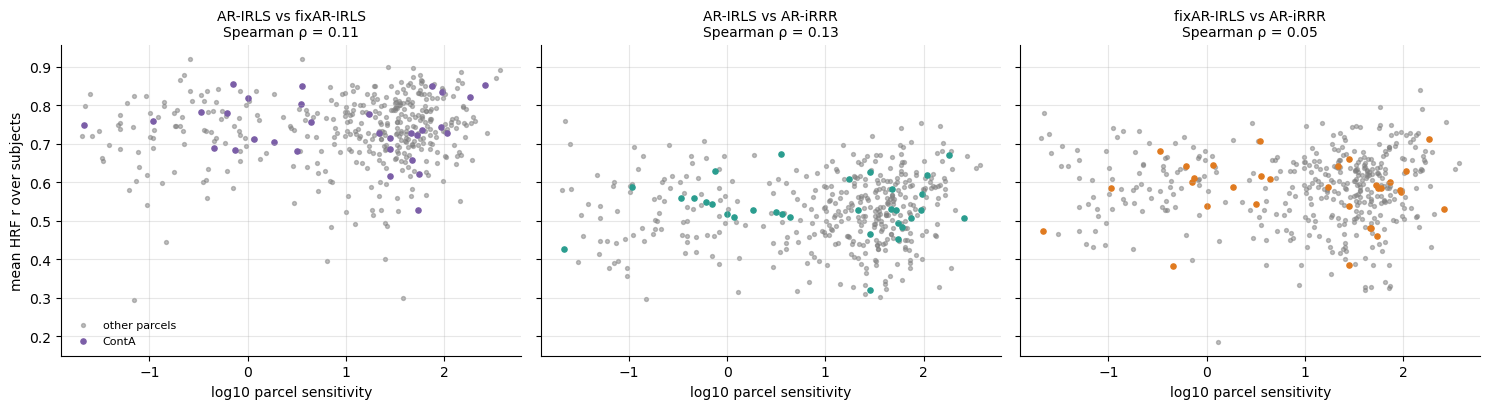

In [11]:
import cedalion.io
Adot = cedalion.io.load_Adot('/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/cedalion/fw/probe/Adot_v26.nc')
Adot_brain = Adot.sel(vertex=Adot.is_brain.values)
Adot_brain = Adot_brain.sel(vertex=~Adot_brain.parcel.isin(['Background+FreeSurfer_Defined_Medial_Wall_LH',
                                                            'Background+FreeSurfer_Defined_Medial_Wall_RH']))
sens_mask = (np.log10(Adot_brain[:, :, 1].sum('channel')) > -2).values
parcel_sensitivity = (Adot_brain.sel(vertex=sens_mask).groupby('parcel').sum('vertex')
                      .sum(['channel', 'wavelength']).to_series())

group_corr = corr_long.groupby(level='parcel').mean()
log_sens = np.log10(parcel_sensitivity.reindex(group_corr.index))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, p in zip(axes, pairs):
    is_net = group_corr.index.str.startswith(select_network + '_')
    ax.scatter(log_sens[~is_net], group_corr.loc[~is_net, p], s=8, color='gray', alpha=0.5, label='other parcels')
    ax.scatter(log_sens[is_net], group_corr.loc[is_net, p], s=14, color=pair_colors[p], label=select_network)
    rho = stats.spearmanr(log_sens, group_corr[p]).correlation
    ax.set_title(f'{p}\nSpearman ρ = {rho:.2f}', fontsize=10)
    ax.set_xlabel('log10 parcel sensitivity')
    ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('mean HRF r over subjects')
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'hrf_corr_vs_sensitivity.png'), dpi=150)
plt.show()

## 9. AR-iRRR temporal components

The rank-2 iRRR coefficient matrix `C` (12 kernels × parcels) factors as `C = U S Vᵀ`. Each column of `B·U` is a temporal component of the HRF; every parcel's iRRR HRF is a mix of these two time courses. The signs are flipped so that each component's largest absolute value is positive. Component 1 explains the larger share of ‖C‖².

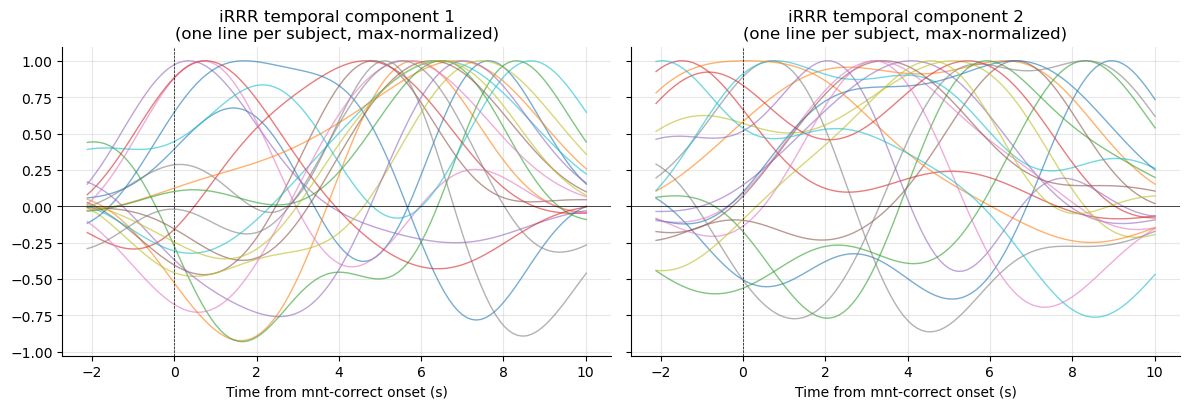

      share comp 1  share comp 2
mean         0.896         0.104
min          0.648         0.001
max          0.999         0.352


In [12]:
B = r0['hrf_basis']
comp_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for s, r in res.items():
    U, S, Vt = np.linalg.svd(r['ar_irrr']['C'], full_matrices=False)
    k = int(r['ar_irrr']['rank'])
    for c in range(min(k, 2)):
        tc = B @ U[:, c]
        tc = tc * np.sign(tc[np.argmax(np.abs(tc))])
        axes[c].plot(hrf_t, tc / np.abs(tc).max(), lw=1, alpha=0.6)
    comp_rows.append({'subject': s, 'share comp 1': S[0] ** 2 / (S ** 2).sum(), 'share comp 2': S[1] ** 2 / (S ** 2).sum()})
for c, ax in enumerate(axes):
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5, ls='--')
    ax.set_title(f'iRRR temporal component {c + 1}\n(one line per subject, max-normalized)')
    ax.set_xlabel('Time from mnt-correct onset (s)')
    ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'irrr_components.png'), dpi=150)
plt.show()
comp_df = pd.DataFrame(comp_rows).set_index('subject')
print(comp_df.describe().loc[['mean', 'min', 'max']].round(3).to_string())

## 10. Per-subject figures

The script saves, for each subject, the HRFs at the most sensitive `ContA` parcel and over the `ContA` network. Pick a subject below; by default, the subjects with the highest and the lowest median AR-IRLS vs fixAR-IRLS agreement over all parcels are shown.

sub-637: median r over all parcels
pair
AR-IRLS vs AR-iRRR       0.72
AR-IRLS vs fixAR-IRLS    0.95
fixAR-IRLS vs AR-iRRR    0.71


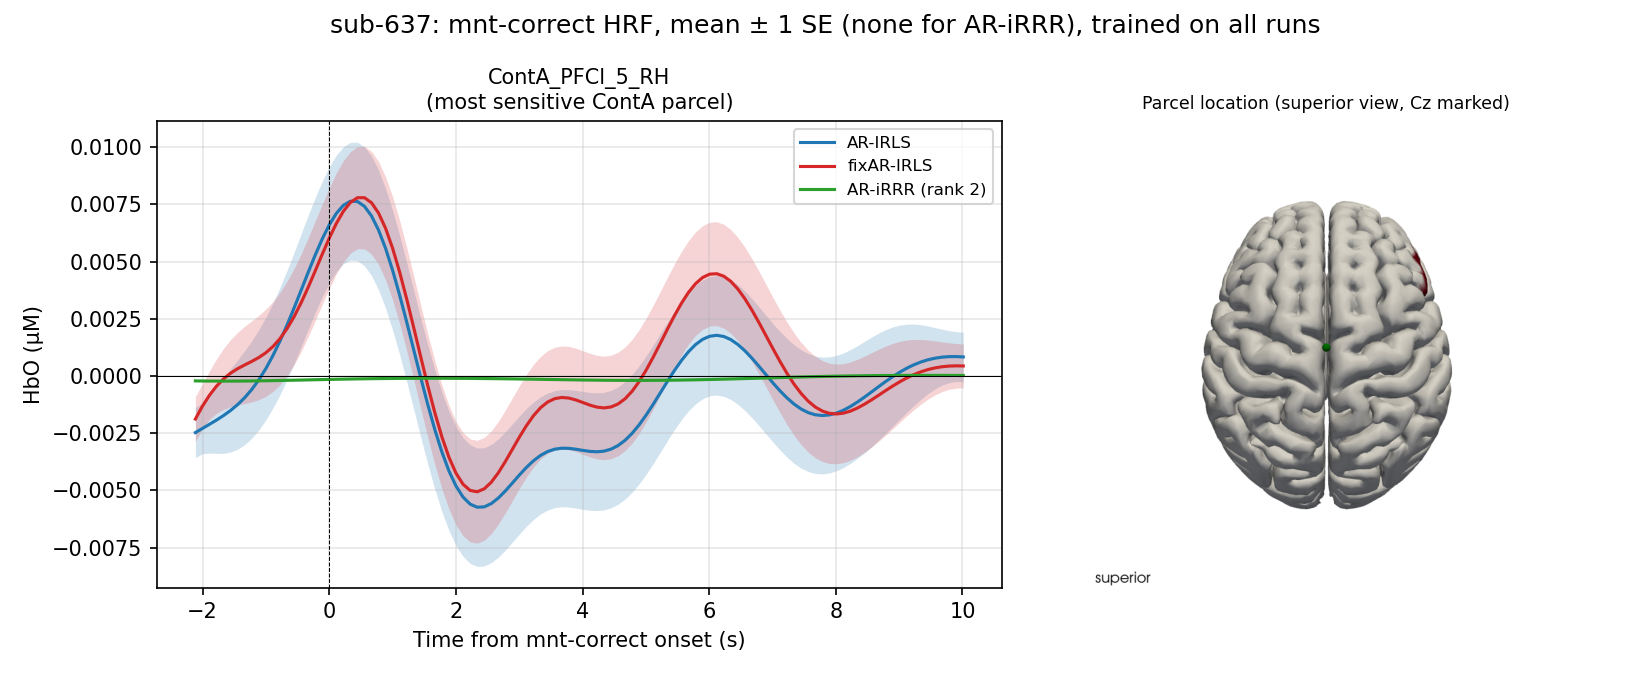

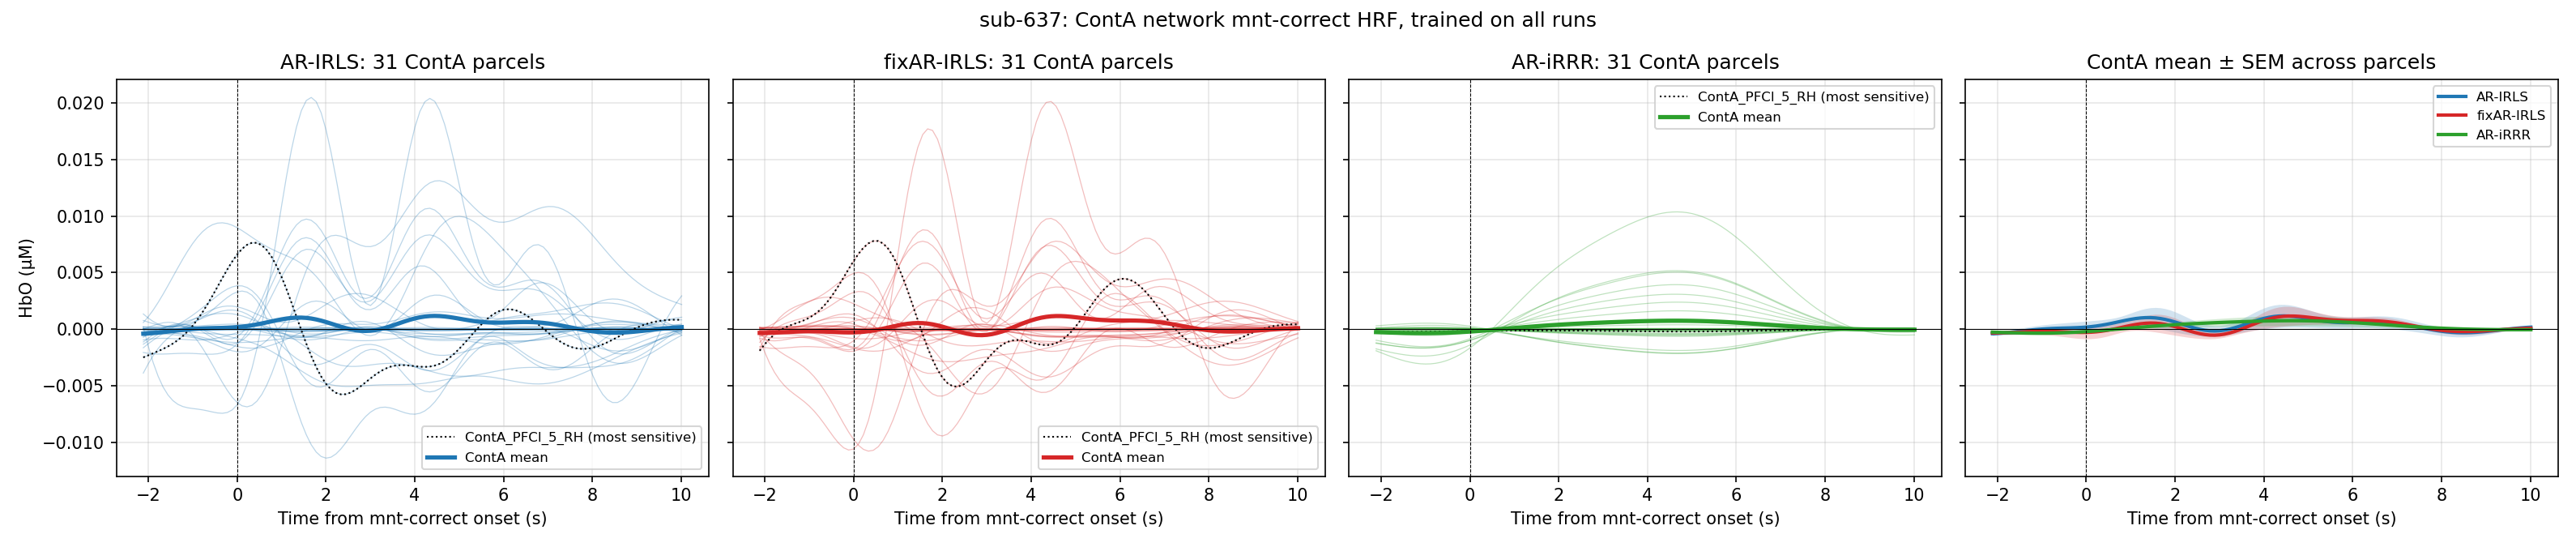

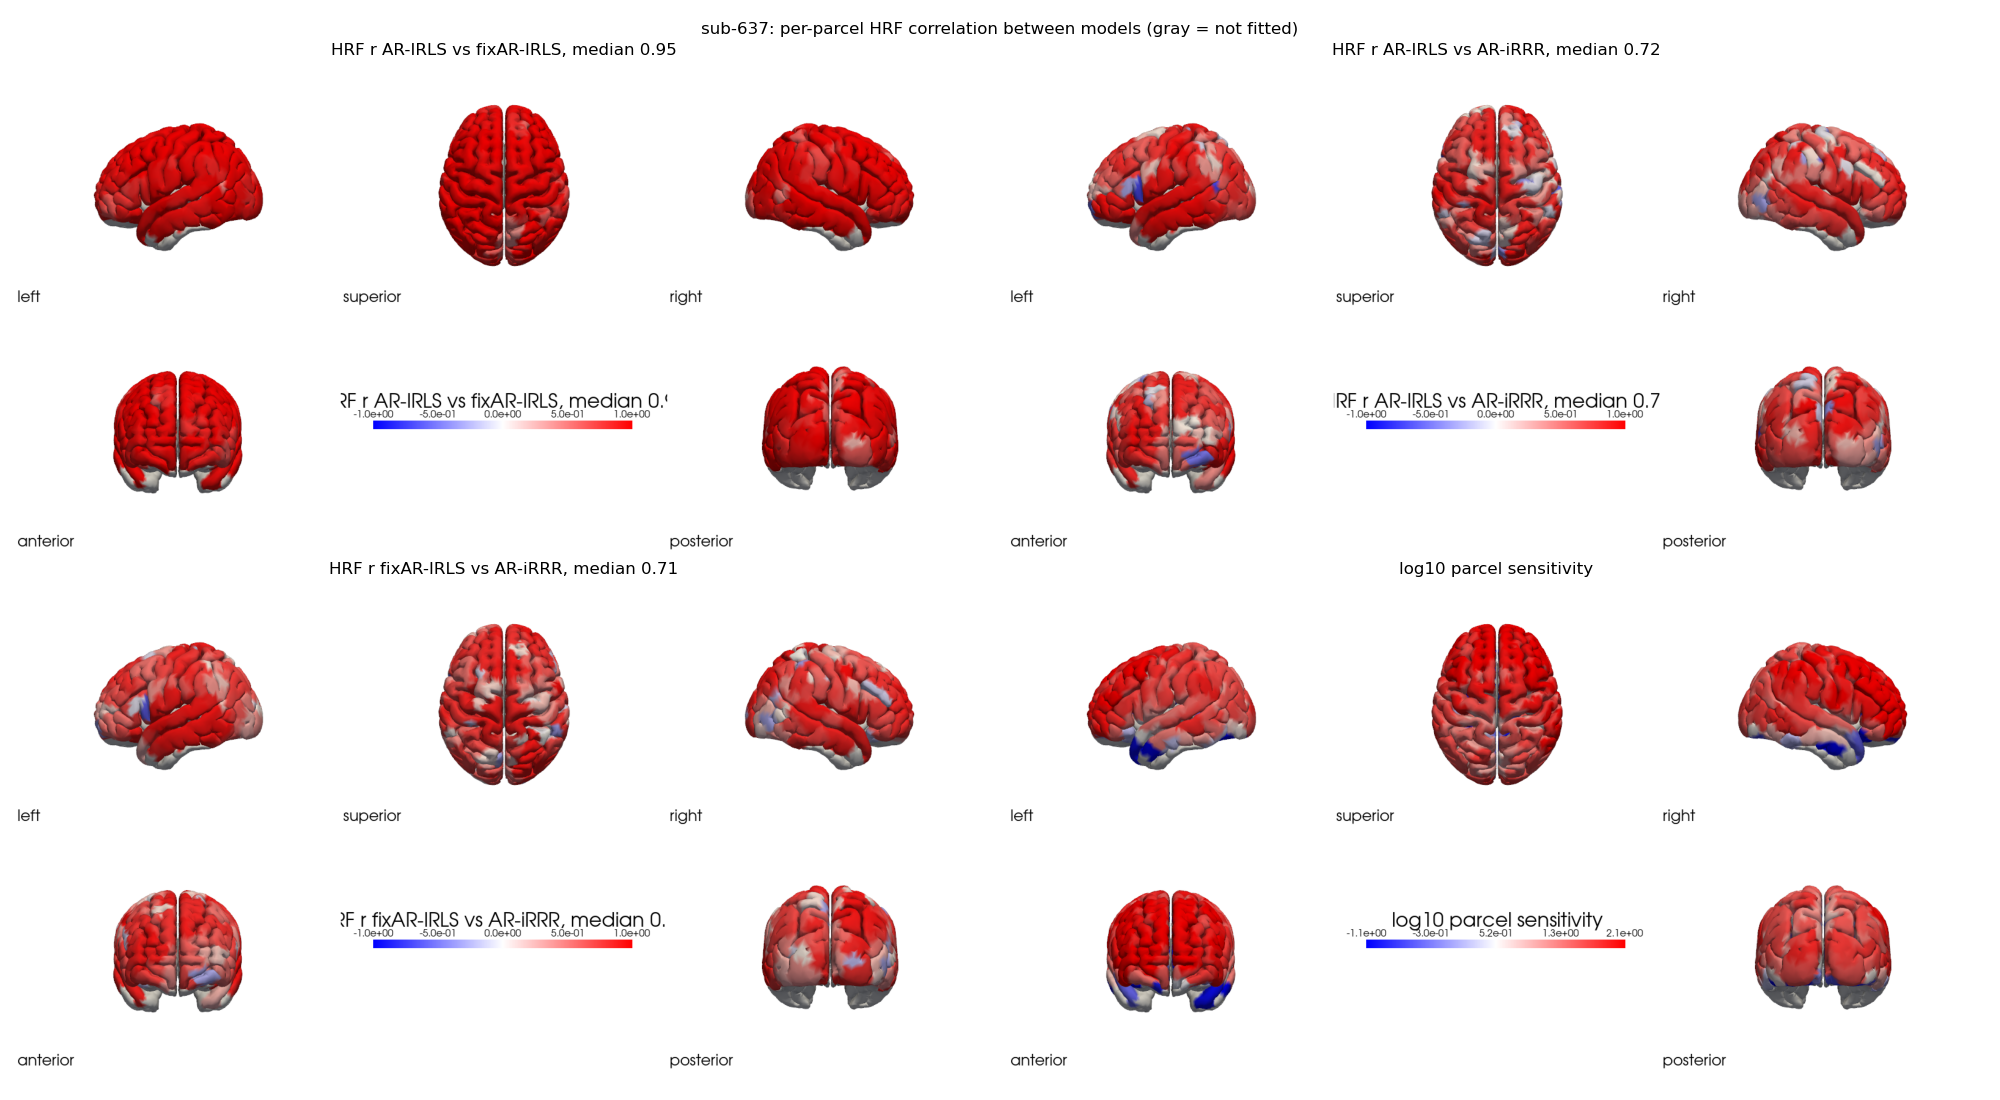

In [13]:
def show_subject(s):
    d = os.path.join(plot_root, s, model_name)
    print(f"{s}: median r over all parcels\n{wide['all'].loc[s].round(2).to_string()}")
    for f in [f'{s}_hrf_{res[s]["select_parcel"]}.png', f'{s}_hrf_network_{select_network}.png', f'{s}_hrf_corr_surf.png']:
        display(Image(os.path.join(d, f), width=1000))

order = wide['all'][pairs[0]].sort_values()
show_subject(order.index[-1])   # best agreement

sub-719: median r over all parcels
pair
AR-IRLS vs AR-iRRR       0.34
AR-IRLS vs fixAR-IRLS    0.51
fixAR-IRLS vs AR-iRRR    0.59


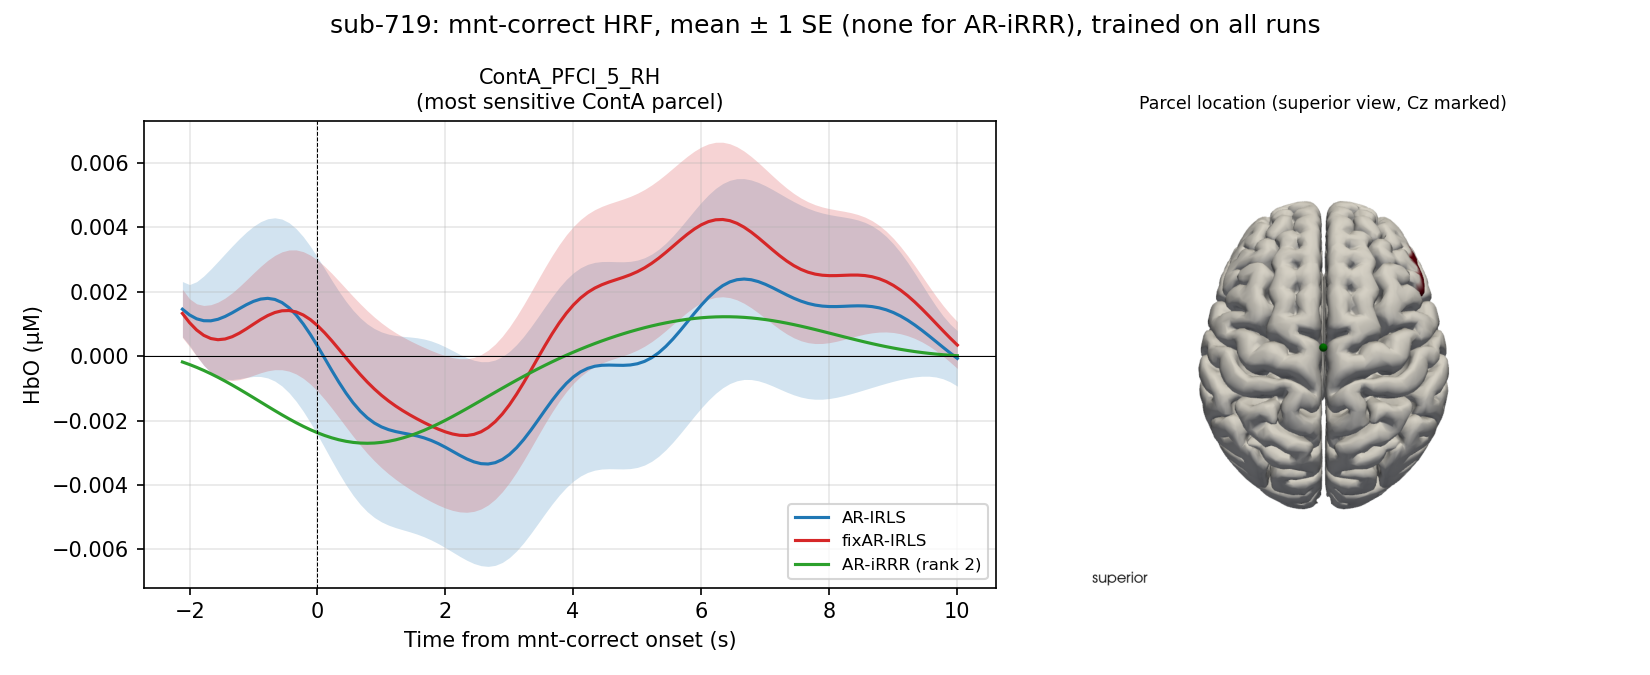

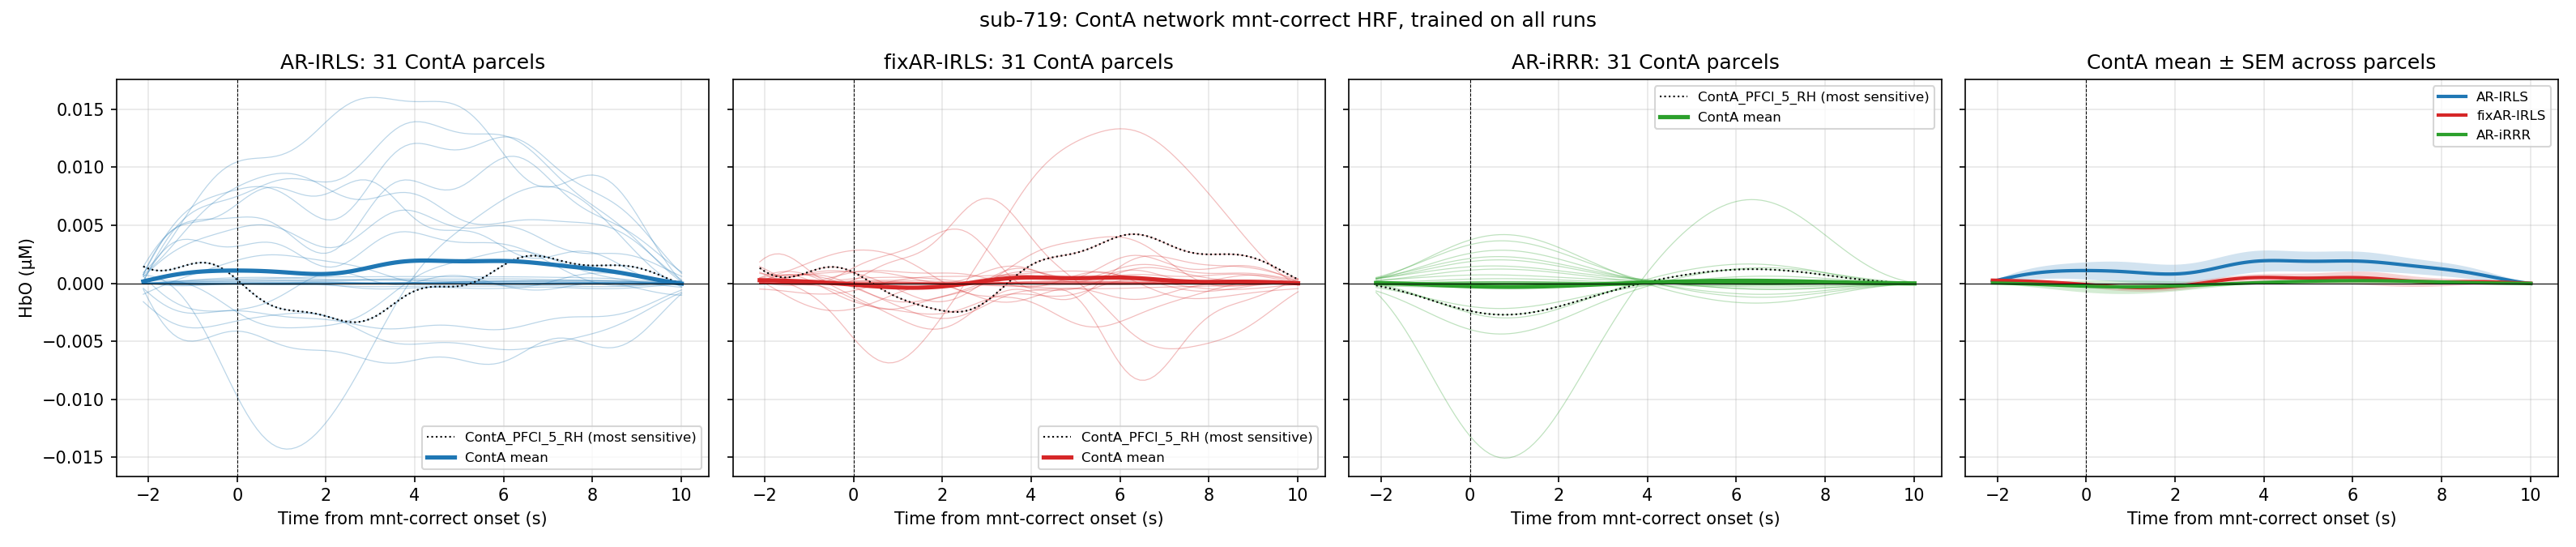

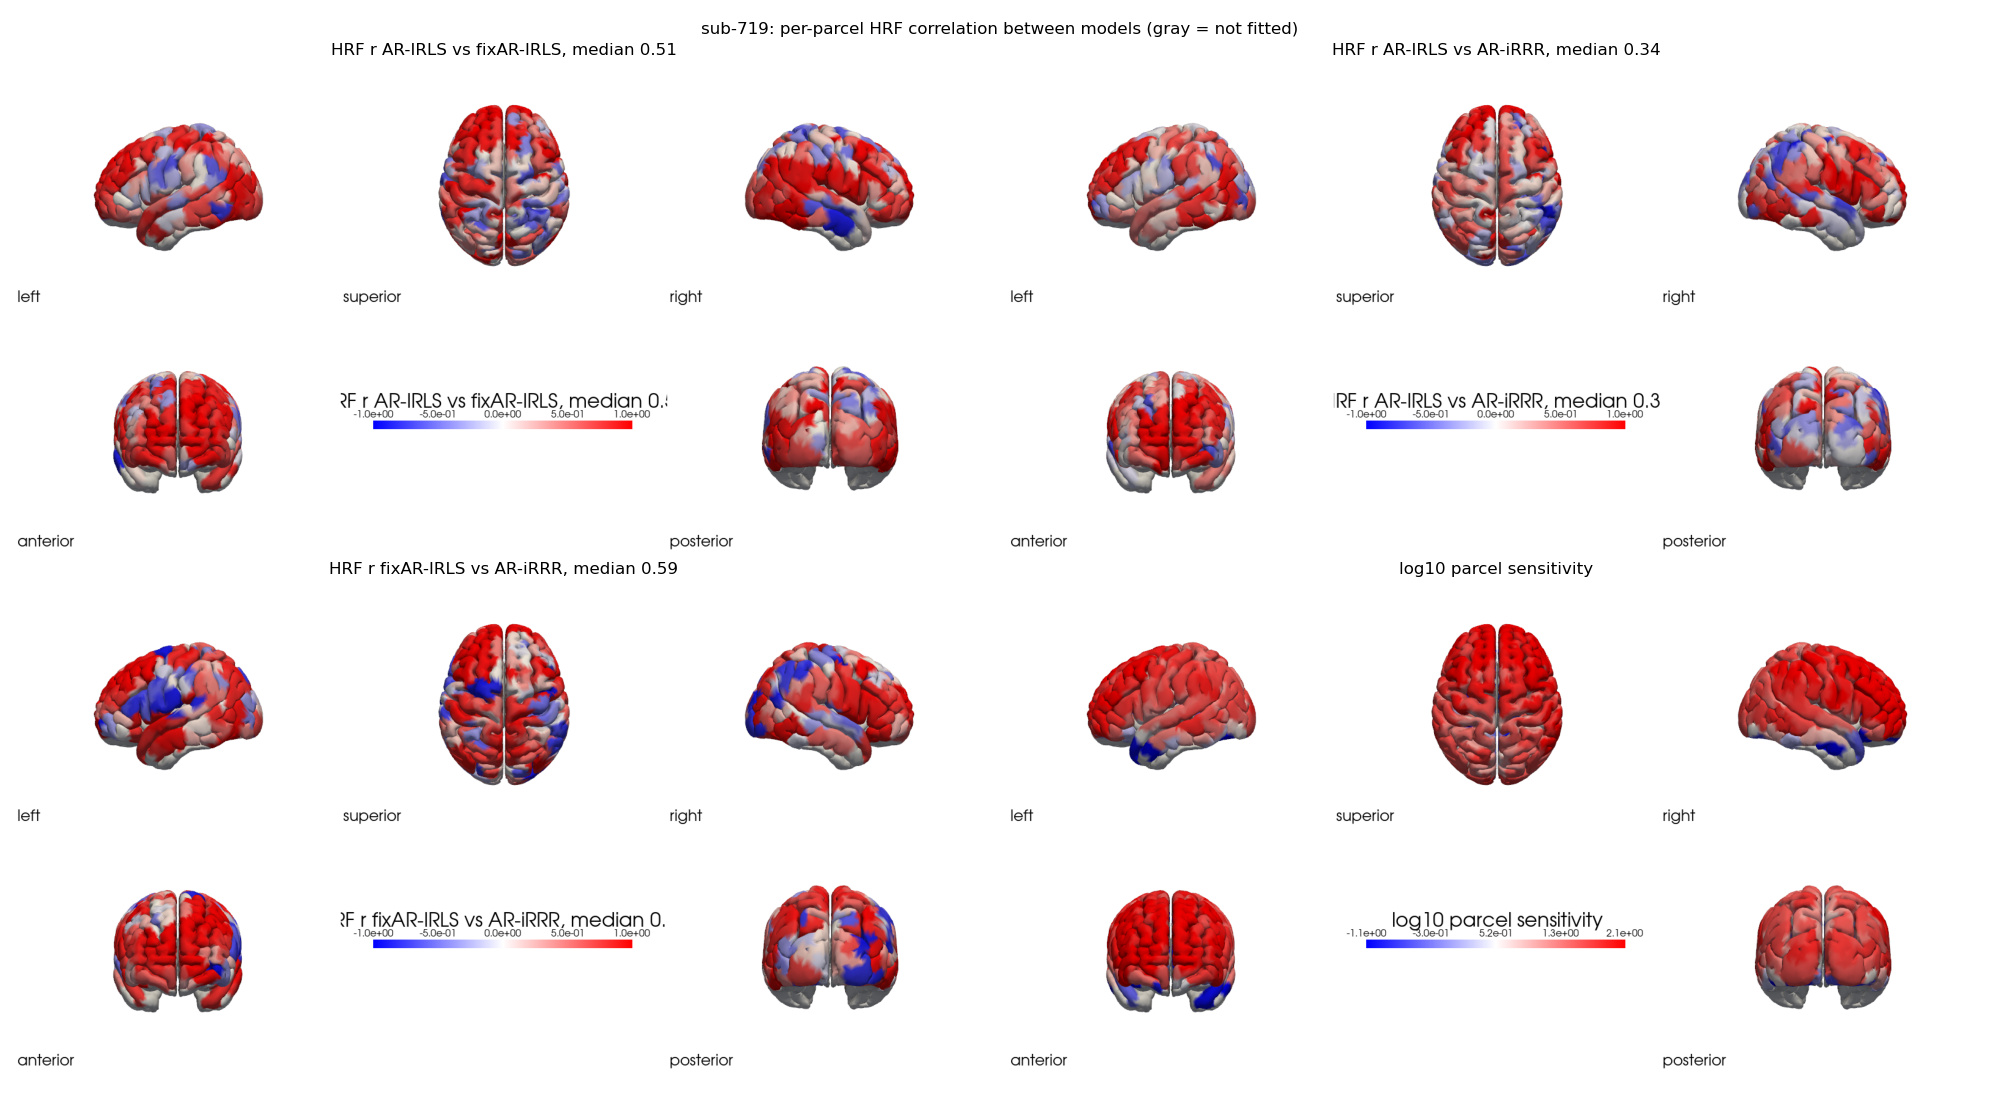

In [14]:
show_subject(order.index[0])    # worst agreement

## 11. Summary

N = 20 subjects, 417 parcels each (31 in `ContA`). iRRR reached rank 2 for every subject, with λ₁ = 0.21–0.56.

**Shape agreement (section 3).**
- **AR-IRLS and fixAR-IRLS agree most:** the median per-parcel `r` is 0.87 (range 0.51–0.95 over subjects). Only 5% of parcels have `r < 0`. The only change between them is the noise model: a per-parcel AR(≤30) vs one spectral kernel shared by all parcels. So the shared kernel changes the HRF shape little.
- **AR-iRRR agrees less** with both: median `r` is 0.70 vs AR-IRLS and 0.77 vs fixAR-IRLS. It is closer to fixAR-IRLS in 16 of 20 subjects (Wilcoxon p = 0.001), as expected, since the two share the same whitened `Y` and `X`. The rest of the gap from fixAR-IRLS (median `r` 0.77, not ~1) comes from the rank-2 constraint.
- The `ContA` parcels give the same picture as all parcels.
- Agreement hardly depends on forward-model sensitivity (Spearman ρ ≤ 0.13). The surface maps are uniformly red, with slightly lower agreement in the temporal/inferior parcels.
- **Outliers:** sub-751 (fixAR-IRLS vs AR-iRRR median `r` = 0.07; AR-IRLS vs AR-iRRR = 0.20) and sub-719 (AR-IRLS vs fixAR-IRLS = 0.51). These two are worth checking individually.

**Amplitude (section 4).**
- fixAR-IRLS HRFs are ~19% smaller than AR-IRLS (median RMS ratio 0.81).
- AR-iRRR HRFs are ~4× smaller (median ratio 0.23, range 0.11–0.54), because of the nuclear-norm shrinkage at the λ₁ that gives rank 2. Compare AR-iRRR HRFs to the other models by shape, not by size.

**Standard errors (section 5).**
- fixAR-IRLS and AR-IRLS have similar SEs (median ratio 0.97; below 1 in 13 of 20 subjects).
- Because fixAR-IRLS amplitudes are smaller, its peak |t| is lower in 19 of 20 subjects (median over subjects 2.4 vs 3.1).

**Group HRF (section 6).**
- The `ContA` network-mean HRF is almost identical for AR-IRLS and fixAR-IRLS (r = 0.98): a positive peak at ~4.5 s and a dip at ~8 s. AR-iRRR gives a smoother, smaller version of the same peak (r = 0.85 / 0.83).
- At the single most sensitive parcel (`ContA_PFCl_5_RH`, the same parcel for every subject), the subjects' HRFs differ widely, and the group mean is small next to that spread for all three models.
- Across networks (section 7), all three pairs of models reach r ≥ 0.90 between the group-mean HRFs in ContC, DefaultB, DorsAttnB, SalVentAttnA and SalVentAttnB. In several networks, the AR-IRLS HRF sits above or below the two whitened models over most of the window, as if shifted by a roughly constant baseline. This gives the low AR-IRLS vs fixAR-IRLS agreement in ContB (r = 0.26), SomMotB (0.54) and DefaultA (0.76). In those networks fixAR-IRLS and AR-iRRR still agree with each other (r = 0.65–0.99).

**AR-iRRR components (section 9).**
- Component 1 carries most of ‖C‖² (mean 90%, range 65–100%).
- The temporal shapes of the components differ across subjects (peak latencies from ~0 to ~9 s). So the rank-2 subspace is not one common HRF shape repeated across subjects.